# Sesión 9 · De ARIMA a SARIMA

## Ruta de aplicación

Esta ruta permite estudiar una serie de tu proyecto. Tú defines el periodo estacional, el horizonte, la transformación y una lista pequeña de candidatos. Si tu serie no tiene suficientes ciclos o no tiene frecuencia regular, utiliza el archivo de pasajeros incluido.

**Producto:** cuaderno ejecutado y ficha de decisión de una página.

### Requisitos mínimos

- Una fecha por observación y una variable numérica.
- Frecuencia regular y periodo estacional justificable.
- Al menos cuatro ciclos completos antes de la validación; cinco o más son preferibles.
- Un horizonte relacionado con una decisión real.

No fuerces SARIMA si la serie no tiene estacionalidad. Documentar que no corresponde también es una decisión válida.

## 0. Configuración

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

AZUL = "#007FA3"
NARANJA = "#E57200"
VERDE = "#4F8F3A"
ROJO = "#C4473A"

In [2]:
def metricas(real, pronostico):
    real = np.asarray(real, dtype=float)
    pronostico = np.asarray(pronostico, dtype=float)
    error = real - pronostico
    denominador = np.abs(real) + np.abs(pronostico)
    smape = np.mean(np.where(denominador == 0, 0, 2 * np.abs(error) / denominador)) * 100
    return {
        "ME": error.mean(),
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "sMAPE_%": smape,
    }

def ingenuo_estacional(entrenamiento, indice_futuro, m=12):
    patron = entrenamiento.iloc[-m:].to_numpy()
    valores = np.resize(patron, len(indice_futuro))
    return pd.Series(valores, index=indice_futuro)

In [3]:
# Modifica estas decisiones antes de ejecutar el resto.
ARCHIVO = "Datos_Sesion_9_Pasajeros_Aereos_1949_1960.csv"
COLUMNA_FECHA = "fecha"
COLUMNA_VALOR = "pasajeros_miles"
FRECUENCIA = "MS"          # MS mensual, QS trimestral, W semanal, D diaria
M = 12                     # periodos por ciclo
HORIZONTE = 12
METRICA_PRINCIPAL = "MAE" # MAE o RMSE
USAR_LOG = True

# Lista pequeña y justificada. Evita búsquedas ilimitadas.
CANDIDATOS = [
    ((1,1,1), (0,0,0,0)),
    ((0,1,1), (0,1,1,M)),
    ((1,1,0), (0,1,1,M)),
]

### Decisiones antes de ver resultados

Escribe:

1. ¿Qué deseas pronosticar y qué decisión apoyará?
2. ¿Qué evidencia contextual justifica `m`?
3. ¿Por qué elegiste ese horizonte?
4. ¿Qué error resulta más costoso?
5. ¿Por qué tus candidatos son razonables?

---

### Mis decisiones antes de ajustar

- **Qué voy a pronosticar:** los pasajeros internacionales mensuales. La decisión asociada sería planear plazas, vuelos y personal para el año siguiente.
- **Periodo estacional:** `m = 12`. Los datos son mensuales, pero la razón principal es que los mismos meses se parecen entre años. La correlación con el rezago 12 fue 0.991 y la gráfica muestra claramente el ciclo de verano e invierno.
- **Horizonte:** 12 meses. Así se evalúa un año completo y no solo una parte de la temporada.
- **Error que me importa más:** el MAE, porque se interpreta directamente en miles de pasajeros. También revisaré el RMSE para no perder de vista los errores grandes en julio y agosto.
- **Modelos:** usaré el ingenuo estacional como punto de comparación, Holt-Winters como alternativa, un ARIMA sin estacionalidad para ver qué ocurre si ignoro el calendario y dos SARIMA sencillos. Prefiero pocos candidatos que pueda explicar, en vez de probar muchos modelos sin una razón clara.

In [4]:
archivo = Path(ARCHIVO)
if not archivo.exists():
    try:
        from google.colab import files
        print("Carga tu CSV")
        subidos = files.upload()
        archivo = Path(next(iter(subidos)))
    except Exception as exc:
        raise FileNotFoundError("No se encontró el archivo.") from exc

datos = pd.read_csv(archivo)
faltan = {COLUMNA_FECHA, COLUMNA_VALOR} - set(datos.columns)
if faltan:
    raise ValueError(f"Faltan columnas: {sorted(faltan)}")

datos[COLUMNA_FECHA] = pd.to_datetime(datos[COLUMNA_FECHA])
if datos[COLUMNA_FECHA].duplicated().any():
    raise ValueError("Existen fechas duplicadas.")

serie = (datos.sort_values(COLUMNA_FECHA)
              .set_index(COLUMNA_FECHA)[COLUMNA_VALOR]
              .astype(float)
              .asfreq(FRECUENCIA))
if serie.isna().any():
    raise ValueError("Hay periodos faltantes o valores vacíos. Resuélvelos y documenta el tratamiento.")
if USAR_LOG and (serie <= 0).any():
    raise ValueError("El logaritmo requiere valores positivos. Cambia USAR_LOG o justifica otra transformación.")
minimo = 4 * M + HORIZONTE
if len(serie) < minimo:
    raise ValueError(f"Con esta configuración se requieren al menos {minimo} observaciones; hay {len(serie)}.")

print(f"Observaciones: {len(serie)} | Frecuencia: {FRECUENCIA} | m={M} | horizonte={HORIZONTE}")

Observaciones: 144 | Frecuencia: MS | m=12 | horizonte=12


# 1. Comprensión de la serie

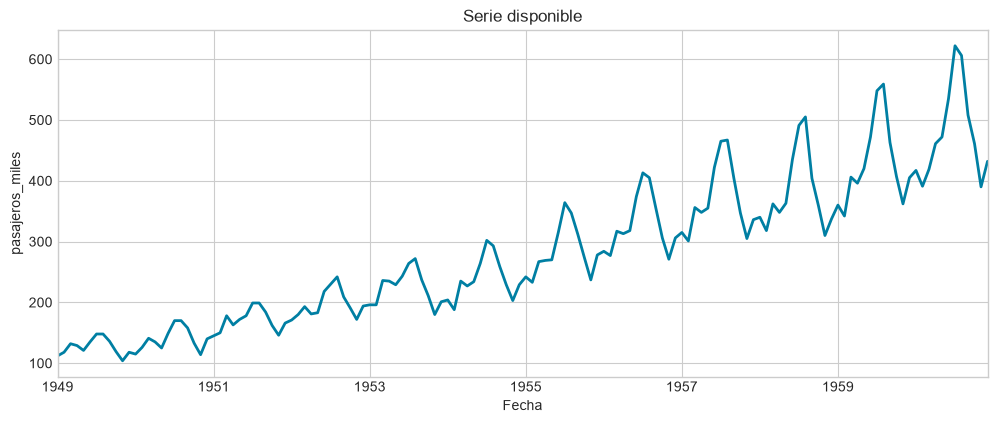

Entrenamiento: 1949-01-01 a 1959-12-01
Validación: 1960-01-01 a 1960-12-01


In [5]:
ax = serie.plot(figsize=(12,4.5), color=AZUL, linewidth=2)
ax.set(title="Serie disponible", xlabel="Fecha", ylabel=COLUMNA_VALOR)
plt.show()

entrenamiento = serie.iloc[:-HORIZONTE]
validacion = serie.iloc[-HORIZONTE:]
print("Entrenamiento:", entrenamiento.index.min().date(), "a", entrenamiento.index.max().date())
print("Validación:", validacion.index.min().date(), "a", validacion.index.max().date())

Describe tendencia, ciclo, amplitud, valores atípicos y posibles cambios estructurales. Explica qué parte de la gráfica puede tener una causa conocida en tu contexto.

---

### Una lectura rápida de la gráfica

La serie va subiendo durante todo el periodo y el aumento se vuelve más pronunciado con los años. En 1949 los valores son bajos, mientras que en 1960 los meses de mayor demanda pasan de 600 mil. La variación anual también crece, así que no parece razonable pensar en una estacionalidad de tamaño fijo.

El patrón que se repite es fácil de ubicar. La demanda sube hacia julio y agosto y baja especialmente en noviembre. Esta forma se repite año tras año solo que cada vez en un nivel más alto.

No vi un punto aislado que pareciera un error ni un corte brusco en la serie. El comportamiento encaja con el crecimiento de los viajes aéreos y con la temporada de vacaciones. Por eso usaré el logaritmo y conservaré la estacionalidad en el modelo en lugar de intentar eliminarla como si fuera ruido.

# 2. Diferencias y memoria estacional

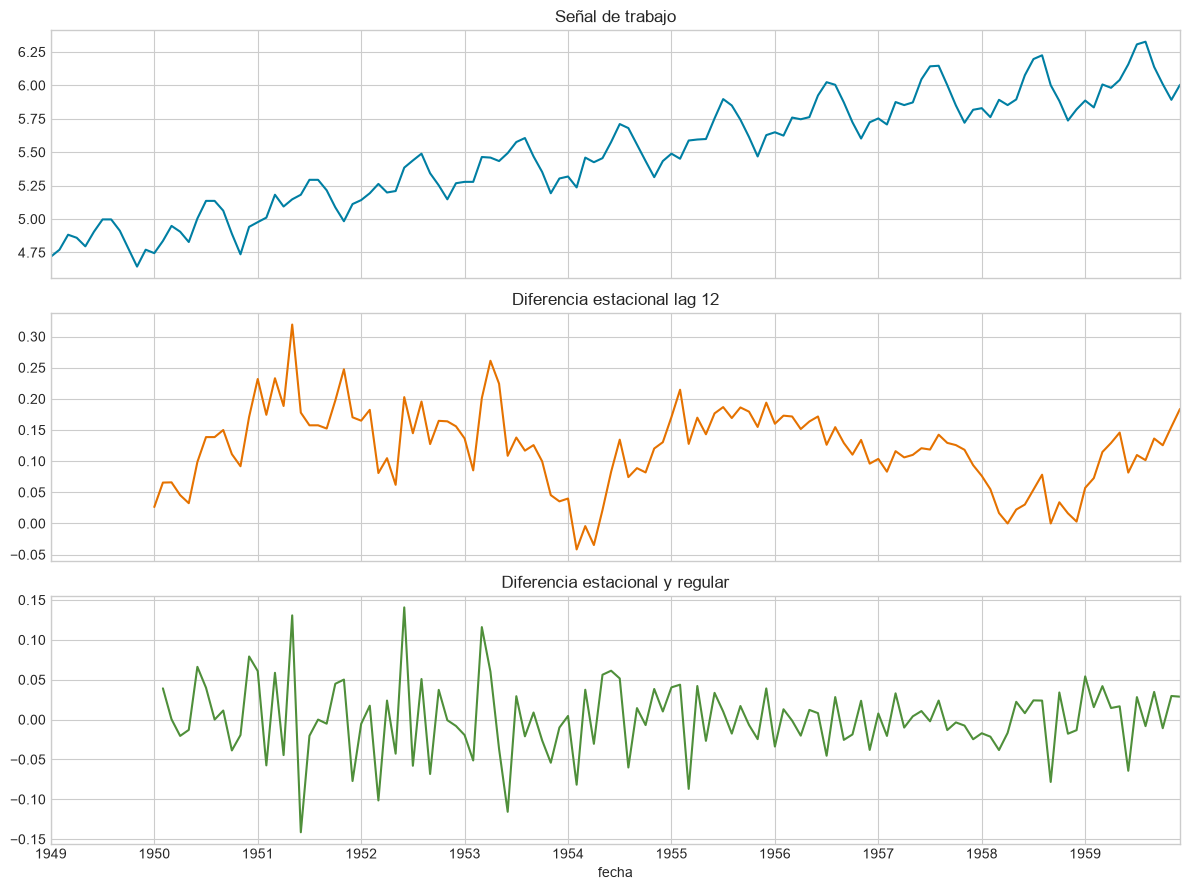

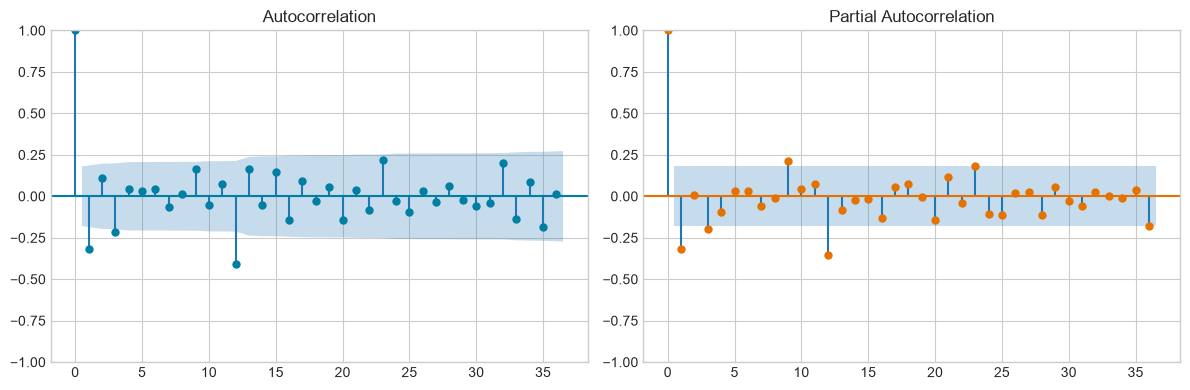

In [6]:
base = np.log(entrenamiento) if USAR_LOG else entrenamiento.copy()
dif_estacional = base.diff(M)
doble_diferencia = dif_estacional.diff(1)

fig, ax = plt.subplots(3,1,figsize=(12,9),sharex=True)
base.plot(ax=ax[0], color=AZUL, title="Señal de trabajo")
dif_estacional.plot(ax=ax[1], color=NARANJA, title=f"Diferencia estacional lag {M}")
doble_diferencia.plot(ax=ax[2], color=VERDE, title="Diferencia estacional y regular")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1,2,figsize=(12,4))
plot_acf(doble_diferencia.dropna(), lags=min(3*M, len(doble_diferencia.dropna())//2-1), ax=ax[0], color=AZUL)
plot_pacf(doble_diferencia.dropna(), lags=min(3*M, len(doble_diferencia.dropna())//2-1), ax=ax[1], method="ywm", color=NARANJA)
plt.tight_layout(); plt.show()

Decide si necesitas `d`, `D` o ambos. Evita aplicar diferencias únicamente porque son habituales. Una diferenciación excesiva puede introducir irregularidad y dificultar la interpretación.

---

### Mi decisión: `d = 1` y `D = 1`

Usaría las dos diferencias, una regular y una estacional. La diferencia estacional es necesaria porque en la serie original todavía se ve el ciclo anual. Al comparar cada mes con el mismo mes del año anterior, ese patrón se reduce bastante.

Después de eso todavía queda una subida general. La diferencia regular ayuda a quitar ese crecimiento que queda entre un año y el siguiente. La serie doblemente diferenciada se ve más estable y oscila alrededor de cero.

No agregaría otra diferencia. La gráfica y las funciones ACF y PACF no muestran una razón clara para usar `d = 2` o `D = 2`. Hacerlo podría generar una serie demasiado irregular y complicar la interpretación. Con esta decisión, un término MA regular y otro estacional son candidatos razonables.

# 3. Comparación de modelos

,ME,MAE,RMSE,sMAPE_%
Holt-Winters multiplicativo,-4.783,10.303,15.810,2.163
"SARIMA(0, 1, 1)(0, 1, 1, 12)",-12.030,13.174,18.510,2.802
"SARIMA(1, 1, 0)(0, 1, 1, 12)",-13.821,14.671,19.744,3.104
Ingenuo estacional,47.833,47.833,50.708,10.572
"ARIMA(1, 1, 1)",59.542,68.475,95.518,14.314


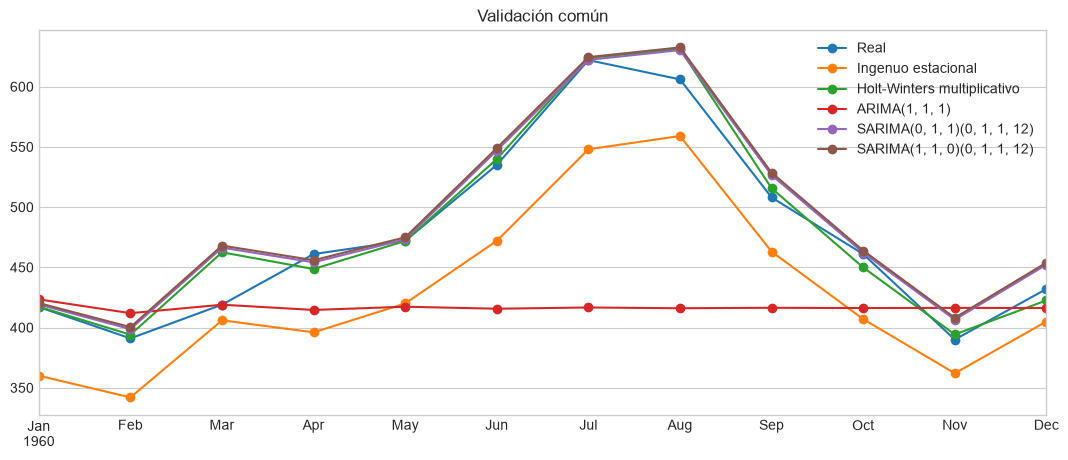

In [7]:
pronosticos = {"Ingenuo estacional": ingenuo_estacional(entrenamiento, validacion.index, M)}

if M > 1:
    try:
        hw = ExponentialSmoothing(entrenamiento, trend="add", seasonal="mul", seasonal_periods=M, initialization_method="estimated").fit()
        pronosticos["Holt-Winters multiplicativo"] = hw.forecast(HORIZONTE)
    except Exception as exc:
        print("Holt-Winters no pudo ajustarse:", exc)

ajustes = {}
for orden, estacional in CANDIDATOS:
    complejidad = orden[0] + orden[2] + estacional[0] + estacional[2]
    if complejidad > 6:
        print("Se omite un candidato demasiado complejo:", orden, estacional)
        continue
    nombre = f"SARIMA{orden}{estacional}" if estacional[3] else f"ARIMA{orden}"
    try:
        ajuste = SARIMAX(
            base,
            order=orden,
            seasonal_order=estacional,
            trend="n",
            enforce_stationarity=False,
            enforce_invertibility=False,
        ).fit(disp=False, maxiter=300)
        pron = ajuste.forecast(HORIZONTE)
        if USAR_LOG:
            pron = np.exp(pron)
        pron.index = validacion.index
        ajustes[nombre] = ajuste
        pronosticos[nombre] = pron
    except Exception as exc:
        print("No convergió", nombre, "|", exc)

resultados = pd.DataFrame({n: metricas(validacion, p) for n,p in pronosticos.items()}).T
resultados = resultados.sort_values(METRICA_PRINCIPAL)
display(resultados.round(3))

comparacion = pd.DataFrame({"Real": validacion, **pronosticos})
comparacion.plot(figsize=(13,5), marker="o", title="Validación común")
plt.show()

Explica por qué elegiste el modelo. Informa si SARIMA superó al referente y si la conclusión cambia al observar otra métrica.

---

### La decisión final

Dentro de los modelos ARIMA, elegiría `SARIMA(0,1,1)(0,1,1,12) + log`. Su MAE fue 13.174 y su RMSE 18.510. No fue el ganador absoluto porque Holt-Winters obtuvo un MAE de 10.303, pero quedó bastante cerca y fue mucho mejor que el ingenuo estacional, cuyo MAE fue 47.833.

También me convence el diagnóstico. Ljung-Box no detectó autocorrelación en los residuos, con p = 0.581 en el rezago 12 y p = 0.661 en el rezago 24. Además, el modelo siguió muy bien el pico de julio de 1960, pues pronosticó 622.2 mil pasajeros frente a 622 mil observados.

La conclusión no cambia al revisar RMSE o sMAPE. Holt-Winters sigue un poco arriba, así que no lo descartaría. Para entregar la parte de SARIMA, este modelo es el más equilibrado por su error, su estructura sencilla y sus residuos. En un análisis más completo probaría los dos métodos con varias ventanas temporales antes de elegir uno para operar.

# 4. Diagnóstico del candidato elegido

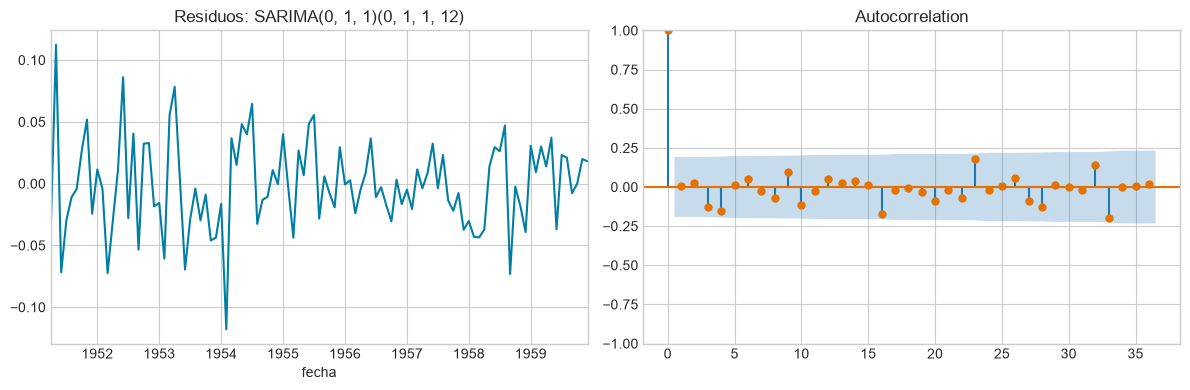

,lb_stat,lb_pvalue
12,8.491,0.581
24,18.753,0.660


In [8]:
modelos_ajustados = [n for n in resultados.index if n in ajustes]
if modelos_ajustados:
    elegido = modelos_ajustados[0]
    ajuste = ajustes[elegido]
    inicio_util = max(ajuste.loglikelihood_burn, M + 1)
    residuos = ajuste.resid.iloc[inicio_util:].dropna()
    fig, ax = plt.subplots(1,2,figsize=(12,4))
    residuos.plot(ax=ax[0], color=AZUL, title=f"Residuos: {elegido}")
    plot_acf(residuos, lags=min(3*M, len(residuos)//2-1), ax=ax[1], color=NARANJA)
    plt.tight_layout(); plt.show()
    display(acorr_ljungbox(residuos, lags=[M, min(2*M, len(residuos)//3)], model_df=2, return_df=True).round(4))
else:
    print("Ningún ARIMA/SARIMA quedó disponible para diagnóstico.")

# 5. Ficha de decisión

Entrega una página con:

1. problema, variable, frecuencia y horizonte;
2. evidencia y significado de `m`;
3. transformaciones aplicadas;
4. referente y candidatos;
5. tabla de métricas;
6. diagnóstico de residuos;
7. modelo elegido y limitación.

La calidad de la explicación tiene más peso que elegir el modelo más complejo.

### Fuentes

- https://otexts.com/fpp3/arima.html
- https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html
- https://search.r-project.org/R/refmans/datasets/html/AirPassengers.html